# **Grafo Epileptogénico bajo la Dinámica Normal**

Preguntas del profesor:

1. No imponer una dinámica fija: $A_{ij}=1$ para todo $i,j$. Ver la matriz de adyacencia de la dinámica normal.
2. Analizar las componentes conexas de la matriz de adyacencia, detectar comunidades con modelos de aprendizaje en grafos y saber qué comunidades están en crisis.
3. Ver cómo entran en crisis las comunidades: primero sin ruido (**Parte I**) y después con ruido (**Parte II**).

Las dos partes hacen el mismo análisis con las mismas funciones; la Parte II solo agrega lo que el ruido hace necesario.

# **Librerías, semilla y parámetros**

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms.community import (louvain_communities, greedy_modularity_communities,
                                           asyn_lpa_communities, modularity)
from scipy.optimize import brentq
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

SEED = 42

TAU0 = 2857.0
I1 = 3.1
X0_C = 2.91                           # umbral epileptogénico (Proix et al. 2014)
UMBRAL_ON, UMBRAL_OFF = -0.5, -1.0    # histéresis: inicio y fin de una crisis
DT = 0.1
T_TRANS = 5000                        # transiente descartado

FIG_DIR = Path("figuras")
FIG_DIR.mkdir(parents=True, exist_ok=True)

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.width", 220)

# **Modelo**

Proix et al. (2014), Ec. 8, con ruido aditivo, para $i=0,\ldots,N-1$:

$$
dx_i=\left(-x_i^3-2x_i^2+1-z_i+I_1\right)dt+\sigma_x\,dW_i^{x},
$$

$$
dz_i=\frac{1}{\tau_0}\left[h(x_i)-z_i-\frac{K}{N}\sum_{j}A_{ij}\,(x_j-x_i)\right]dt+\sigma_z\,dW_i^{z},
$$

$$
h(x)=x_{0,i}+\frac{3}{1+\exp\!\left(\frac{-x-0.5}{0.1}\right)},\qquad \tau_0=2857,\qquad I_1=3.1 .
$$

$x_{0,i}<2.91$: región epileptogénica (foco); $x_{0,i}>2.91$: región sana.

**Regiones:** $N=10$, foco $x_0=[2.3,\,2.4]$ (nodos 0 y 1) y sanas uniformes en $[2.9,3.5]$, con el mismo sorteo (`generate_x0`, semilla 42) de los notebooks anteriores. Si una sana queda con $x_0<2.95$ se vuelve a sortear, para que ninguna quede pegada al umbral.

In [2]:
def h(x, x0):
    return x0 + 3.0 / (1.0 + np.exp((-np.asarray(x) - 0.5) / 0.1))

def nulclina_x(x):
    return -x**3 - 2*x**2 + 1 + I1

def reposo(x0_val):
    return brentq(lambda x: nulclina_x(x) - h(x, x0_val), -3.0, -4.0/3.0)

def generate_x0(N=10, seed=42, x0_min_sana=2.95):
    local_rng = np.random.default_rng(seed)
    x0 = local_rng.normal(2.5, 0.5, N)
    x0[0] = 2.3
    x0[1] = 2.4
    x0[2:] = local_rng.uniform(2.9, 3.5, N - 2)
    resortear = np.arange(N) >= 2
    while (malas := resortear & (x0 < x0_min_sana)).any():
        x0[malas] = local_rng.uniform(2.9, 3.5, malas.sum())
    return x0

N = 10
x0 = generate_x0(N, SEED)
foco = x0 < X0_C
sanas = ~foco

print("x0 =", x0)
print("Foco (epileptogénicas):", np.where(foco)[0], "   sanas:", np.where(sanas)[0])

x0 = [2.3   2.4   3.122 3.456 3.286 3.394 3.166 3.036 3.233 3.397]
Foco (epileptogénicas): [0 1]    sanas: [2 3 4 5 6 7 8 9]


# **Integrador Euler–Maruyama**

Un solo integrador para las dos partes: con $\sigma_x=\sigma_z=0$ es el caso determinista. Simula $M$ realizaciones en paralelo (arreglos $M\times N$ de numpy), cada una con su propio $K$, $\sigma_x$ y $\sigma_z$.

- **Condición inicial:** las sanas en su punto fijo de reposo y el foco en $x=-1.5$, $z=h(x)$.
- **Crisis con histéresis:** una región entra en crisis si $x_i>-0.5$ y sale si $x_i<-1.0$.
- **Salidas** (después del transiente de 5000): número de crisis por región y, si `guardar=True`, las series $x$, $z$ y el estado de crisis cada `cada` pasos.

In [3]:
def ci_reposo(x0):
    x = np.array([reposo(a) if a > X0_C else -1.5 for a in x0])
    return x, h(x, x0)

def em_red(x0, A, K, sx=0.0, sz=0.0, T=60000, dt=DT, M=1, seed=SEED, t_trans=T_TRANS, cada=10, guardar=False):
    x0 = np.asarray(x0, float); N = len(x0)
    A = np.asarray(A, float); grado = A.sum(1)
    K, sx, sz = (np.broadcast_to(np.asarray(v, float), (M,))[:, None] for v in (K, sx, sz))
    KN = K / N
    hay_ruido = (sx > 0).any() or (sz > 0).any()
    rng = np.random.default_rng(seed)
    sq = np.sqrt(dt)
    xi, zi = ci_reposo(x0)
    x = np.tile(xi, (M, 1)); z = np.tile(zi, (M, 1))
    S = x > UMBRAL_ON
    n = int(round(T / dt)); n_trans = int(round(t_trans / dt))
    n_on = np.zeros((M, N), np.int64)
    nrec = (n - n_trans) // cada if guardar else 0
    X = np.empty((nrec, M, N), np.float32); Z = np.empty_like(X); SS = np.empty((nrec, M, N), bool)
    for k in range(1, n + 1):
        acople = x @ A.T - grado * x                       # sum_j A_ij (x_j - x_i)
        hx = x0 + 3.0 / (1.0 + np.exp((-x - 0.5) / 0.1))
        dx = (-x*x*x - 2.0*x*x + 1.0 - z + I1) * dt
        dz = (hx - z - KN * acople) * (dt / TAU0)
        if hay_ruido:
            dx += sx * sq * rng.standard_normal((M, N))
            dz += sz * sq * rng.standard_normal((M, N))
        x += dx; z += dz
        arriba = x > UMBRAL_ON
        inicio = arriba & ~S
        S = arriba | (S & (x >= UMBRAL_OFF))
        if k > n_trans:
            n_on += inicio
            if guardar and (k - n_trans) % cada == 0:
                r = (k - n_trans) // cada - 1
                X[r] = x; Z[r] = z; SS[r] = S
    out = dict(n_on=n_on)
    if guardar:
        out.update(t=np.arange(1, nrec + 1) * cada * dt, x=X, z=Z, ict=SS)
    return out

# **Funciones comunes**

- `matriz_dinamica(Z)`: matriz de adyacencia de la dinámica normal, $W_{ij}=\max(\operatorname{corr}(z_i,z_j),0)$, $W_{ii}=0$.
- `comunidades_clasicas(W)`: Louvain, Greedy (CNM), propagación de etiquetas y espectral (laplaciano normalizado + k-medias, $k$ por la brecha espectral). Tabla con comunidades, modularidad $Q$ y ARI respecto de {foco, sanas}.
- `comunidades_consenso(W)`: Louvain 50 veces con semillas distintas, matriz de coasignación $P_{ij}$ y comunidades = **componentes conexas** del grafo $P_{ij}>0.5$.
- `tabla_crisis(S, comunidades)`: una comunidad está en crisis en $t$ si más de la mitad de sus miembros lo está.
- `comunidades_en_el_tiempo(Z, S, t)`: ventanas deslizantes de 15000 con paso 2500; en cada una, consenso sobre $W$, pertenencia a la comunidad del nodo 0 y fracción de la ventana con la comunidad de cada región en crisis. Con `instantaneas=True` dibuja los clusters antes, durante y después de la cascada.
- `graficar_clusters(W, particiones)`: un panel por método con el mismo layout (`spring_layout` sobre $W$), nodos y aristas internas coloreados por comunidad, aristas con grosor $\propto W_{ij}$, y un panel final con $W$ reordenada por las comunidades del consenso.
- `analizar(Z, S)`: los pasos de I.3 y II.2 (mapa de $W$, grafo de consenso y sus componentes conexas, tabla de comunidades, `graficar_clusters` y `tabla_crisis`).

In [4]:
COLOR_NODO = np.where(foco, "crimson", "royalblue")
POS = nx.circular_layout(nx.complete_graph(N))
ORDEN = np.argsort(x0)                                   # regiones ordenadas por x0
REF = foco.astype(int)                                   # partición {foco, sanas}
CONSENSO = "Consenso (50 Louvain)"

def matriz_dinamica(Z):
    with np.errstate(invalid="ignore", divide="ignore"):
        C = np.nan_to_num(np.corrcoef(np.asarray(Z, float).T))
    W = np.clip(C, 0.0, None)
    np.fill_diagonal(W, 0.0)
    return W

def etiquetas(particion):
    lab = np.empty(N, int)
    for k, c in enumerate(particion):
        lab[list(c)] = k
    return lab

def fila_particion(nombre, G, p):
    p = sorted((sorted(c) for c in p), key=min)
    Q = modularity(G, p, weight="weight") if G.size(weight="weight") > 0 else np.nan
    return {"método": nombre, "comunidades": p, "Q": Q, "ARI vs {foco, sanas}": adjusted_rand_score(REF, etiquetas(p))}

def espectral(W, seed=SEED):
    d = W.sum(1).clip(1e-12)
    L = np.eye(len(W)) - W / np.sqrt(np.outer(d, d))
    val, vec = np.linalg.eigh(L)
    k = max(2, int(np.argmax(np.diff(val[:len(W) // 2 + 1]))) + 1)   # brecha espectral
    U = vec[:, :k]
    U = U / np.linalg.norm(U, axis=1, keepdims=True).clip(1e-12)
    lab = KMeans(k, n_init=10, random_state=seed).fit_predict(U)
    return [set(np.where(lab == c)[0]) for c in np.unique(lab)]

def comunidades_clasicas(W, seed=SEED):
    G = nx.from_numpy_array(W)
    metodos = {
        "Louvain": lambda: louvain_communities(G, weight="weight", seed=seed),
        "Greedy (CNM)": lambda: greedy_modularity_communities(G, weight="weight"),
        "Propagación de etiquetas": lambda: asyn_lpa_communities(G, weight="weight", seed=seed),
        "Espectral": lambda: espectral(W, seed),
    }
    particiones = {nombre: sorted((sorted(c) for c in f()), key=min) for nombre, f in metodos.items()}
    tabla = pd.DataFrame([fila_particion(nombre, G, p) for nombre, p in particiones.items()])
    return tabla, particiones

def comunidades_consenso(W, n_rep=50):
    G = nx.from_numpy_array(W)
    P = np.zeros((N, N))
    for s in range(n_rep):
        lab = etiquetas(louvain_communities(G, weight="weight", seed=s))
        P += lab[:, None] == lab[None, :]
    P /= n_rep
    G_P = nx.from_numpy_array((P > 0.5).astype(int))
    comunidades = sorted((sorted(c) for c in nx.connected_components(G_P)), key=min)
    return comunidades, P

def en_crisis(S, comunidad):
    return S[:, comunidad].mean(1) > 0.5

def tabla_crisis(S, comunidades):
    return pd.DataFrame([{"comunidad": k, "miembros": c, "x0 medio": x0[c].mean(),
                          "fracción del tiempo en crisis": en_crisis(S, c).mean()}
                         for k, c in enumerate(comunidades)])

def graficar_clusters(W, particiones, titulo, archivo):
    G_W = nx.from_numpy_array(W)
    pos = nx.spring_layout(G_W, weight="weight", seed=SEED)
    w_max = max(W.max(), 1e-12)
    borde = np.where(foco, "crimson", "white").tolist()
    grosor_borde = np.where(foco, 3.0, 1.0).tolist()
    n = len(particiones) + 1
    fig, ax = plt.subplots(1, n, figsize=(4.3 * n, 4.8))
    for a, (nombre, p) in zip(ax, particiones.items()):
        lab = etiquetas(p)
        color = plt.cm.tab10(lab % 10)
        cruzan = [(i, j) for i, j in G_W.edges if lab[i] != lab[j]]
        internas = [(i, j) for i, j in G_W.edges if lab[i] == lab[j]]
        for aristas, colores in [(cruzan, ["0.85"] * len(cruzan)), (internas, [color[i] for i, _ in internas])]:
            if aristas:
                nx.draw_networkx_edges(G_W, pos, edgelist=aristas, ax=a, edge_color=colores,
                                       width=[4 * W[i, j] / w_max for i, j in aristas])
        nx.draw_networkx_nodes(G_W, pos, ax=a, node_color=color, edgecolors=borde, linewidths=grosor_borde,
                               node_size=650)
        nx.draw_networkx_labels(G_W, pos, {i: f"{i}\n({x0[i]:.2f})" for i in range(N)}, ax=a, font_size=7)
        fila = fila_particion(nombre, G_W, p)
        Q, ARI = fila["Q"], fila["ARI vs {foco, sanas}"]
        a.set_title(f"{nombre}\n{len(p)} comunidades, Q = {Q:.3f}, ARI = {ARI:.2f}", fontsize=9)
        a.axis("off")
    com = particiones[CONSENSO]
    orden = np.concatenate([np.array(c)[np.argsort(x0[c])] for c in com])   # por x0 dentro de cada comunidad
    a = ax[-1]
    im = a.imshow(W[np.ix_(orden, orden)], cmap="viridis", vmin=0)
    a.set_xticks(range(N), orden, fontsize=7)
    a.set_yticks(range(N), [f"{i} ({x0[i]:.2f})" for i in orden], fontsize=7)
    inicio = 0
    for k, c in enumerate(com):
        a.add_patch(plt.Rectangle((inicio - 0.5, inicio - 0.5), len(c), len(c), fill=False,
                                  edgecolor=plt.cm.tab10(k % 10), lw=2.5))
        inicio += len(c)
    a.set_title("W reordenada por las comunidades del consenso", fontsize=9)
    plt.colorbar(im, ax=a, fraction=0.046)
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(FIG_DIR / archivo, dpi=200)
    plt.show()

def analizar(Z, S, titulo, archivo):
    W = matriz_dinamica(Z)
    com, _ = comunidades_consenso(W)
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(W, cmap="viridis", vmin=0)
    ax.set_xticks(range(N)); ax.set_yticks(range(N))
    ax.set(xlabel="j", ylabel="i", title=rf"{titulo}: $W_{{ij}}=\max(\mathrm{{corr}}(z_i,z_j),0)$")
    plt.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(FIG_DIR / archivo, dpi=200)
    plt.show()
    print(f"Componentes conexas del grafo de consenso: {len(com)}  ->  {com}")
    G = nx.from_numpy_array(W)
    tabla, particiones = comunidades_clasicas(W)
    particiones[CONSENSO] = com
    tabla = pd.concat([tabla, pd.DataFrame([fila_particion(CONSENSO, G, com)])], ignore_index=True)
    display(tabla.round(3))
    graficar_clusters(W, particiones, titulo, archivo.replace(".png", "_clusters.png"))
    tc = tabla_crisis(S, com)
    display(tc.round(3))
    return W, com, tc

def comunidades_en_el_tiempo(Z, S, t, titulo, archivo, ventana=15000, paso=2500, instantaneas=False):
    dt_reg = t[1] - t[0]
    nv, npaso = int(round(ventana / dt_reg)), int(round(paso / dt_reg))
    inicios = np.arange(0, len(t) - nv + 1, npaso)
    centros = t[inicios] + ventana / 2
    pert = np.zeros((len(inicios), N)); frac = np.zeros((len(inicios), N))
    tam = np.zeros(len(inicios), int); ncom = np.zeros(len(inicios), int)
    for w, a in enumerate(inicios):
        sl = slice(a, a + nv)
        com, _ = comunidades_consenso(matriz_dinamica(Z[sl]))
        c_foco = next(c for c in com if 0 in c)
        pert[w, c_foco] = 1
        for c in com:
            frac[w, c] = en_crisis(S[sl], c).mean()
        tam[w], ncom[w] = len(c_foco), len(com)

    etiq = [f"{i} ({x0[i]:.2f})" for i in ORDEN]
    ext = [centros[0] - paso / 2, centros[-1] + paso / 2, -0.5, N - 0.5]
    fig, ax = plt.subplots(4, 1, figsize=(13, 12), sharex=True, gridspec_kw=dict(height_ratios=[1, 1, 1, 0.7]))
    ax[0].imshow(S[:, ORDEN].T, aspect="auto", origin="lower", cmap="Greys", interpolation="nearest",
                 extent=[t[0], t[-1], -0.5, N - 0.5])
    ax[0].set_title("(a) Estado de crisis (negro = en crisis)")
    ax[1].imshow(pert[:, ORDEN].T, aspect="auto", origin="lower", cmap="Reds", vmin=0, vmax=1,
                 interpolation="nearest", extent=ext)
    ax[1].set_title("(b) Pertenencia a la comunidad del foco (rojo = misma comunidad que el nodo 0)")
    im = ax[2].imshow(frac[:, ORDEN].T, aspect="auto", origin="lower", cmap="magma_r", vmin=0,
                      vmax=max(frac.max(), 1e-3), interpolation="nearest", extent=ext)
    ax[2].set_title("(c) Fracción de la ventana con la comunidad de cada región en crisis")
    fig.colorbar(im, ax=ax[2], location="right", fraction=0.02, pad=0.01)
    for a in ax[:3]:
        a.set_yticks(range(N), etiq, fontsize=8)
        a.set_ylabel("región (x0)")
    ax[3].step(centros, tam, where="mid", color="crimson", label="tamaño de la comunidad del foco")
    ax[3].step(centros, ncom, where="mid", color="k", ls="--", label="número de comunidades")
    ax[3].set(xlabel="t", ylim=(0, N + 0.5), title="(d) Comunidad del foco y número de comunidades")
    ax[3].legend(fontsize=8, loc="upper left"); ax[3].grid(alpha=0.3)
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(FIG_DIR / archivo, dpi=200)
    plt.show()

    if instantaneas:
        n_sanas = np.array([S[a:a + nv][:, sanas].any(0).sum() for a in inicios])   # sanas con crisis en la ventana
        n_simul = np.array([S[a:a + nv].sum(1).max() for a in inicios])            # regiones en crisis a la vez
        w_dur = int(np.argmax(n_simul))
        quietas = np.where(n_sanas == 0)[0]
        antes, despues = quietas[quietas < w_dur], quietas[quietas > w_dur]
        etapas = {"antes": antes[-1] if len(antes) else None, "durante": w_dur,
                  "despues": despues[0] if len(despues) else None}
        for etapa, w in etapas.items():
            nombre = etapa.replace("despues", "después")
            if w is None:
                print(f"No hay ventana {nombre} de la cascada sin crisis sanas.")
                continue
            sl = slice(inicios[w], inicios[w] + nv)
            W_v = matriz_dinamica(Z[sl])
            com_v, _ = comunidades_consenso(W_v)
            t_a, t_b = t[inicios[w]], t[inicios[w]] + ventana
            print(f"{nombre}: t ∈ [{t_a:.0f}, {t_b:.0f}], regiones en crisis a la vez: {n_simul[w]}, "
                  f"sanas con crisis: {n_sanas[w]}, comunidades del consenso: {com_v}")
            graficar_clusters(W_v, {CONSENSO: com_v}, f"{titulo}: {nombre} de la cascada (t ∈ [{t_a:.0f}, {t_b:.0f}])",
                              archivo.replace(".png", f"_{etapa}.png"))

    primera_crisis = np.array([t[np.argmax(S[:, i])] if S[:, i].any() else np.nan for i in range(N)])
    primera_vent = np.array([centros[np.argmax(pert[:, i])] if pert[:, i].any() else np.nan for i in range(N)])
    resumen = pd.DataFrame({"x0": x0, "primera crisis (t)": primera_crisis,
                            "primera ventana en la comunidad del foco (t)": primera_vent,
                            "fracción de ventanas en la comunidad del foco": pert.mean(0),
                            "fracción media en crisis de su comunidad": frac.mean(0)},
                           index=pd.Index(range(N), name="región")).iloc[ORDEN]
    display(resumen.round(3))
    return resumen

# **Parte I: Dinámica normal determinista ($\sigma_x=\sigma_z=0$)**

# **I.1 Grafo de la dinámica normal**

No se impone ninguna dinámica: $A_{ij}=1$ para todo $i\neq j$. La diagonal no influye, porque $x_i-x_i=0$, así que se deja en 0.

Como $A$ no distingue regiones, la estructura se mide en la dinámica con $W_{ij}=\max(\operatorname{corr}(z_i,z_j),0)$. Se usa $z$ porque es la variable lenta, por donde actúa el acoplamiento de permitividad, y no la dominan las excursiones rápidas de $x$ durante las crisis.

Componentes conexas de A: 1


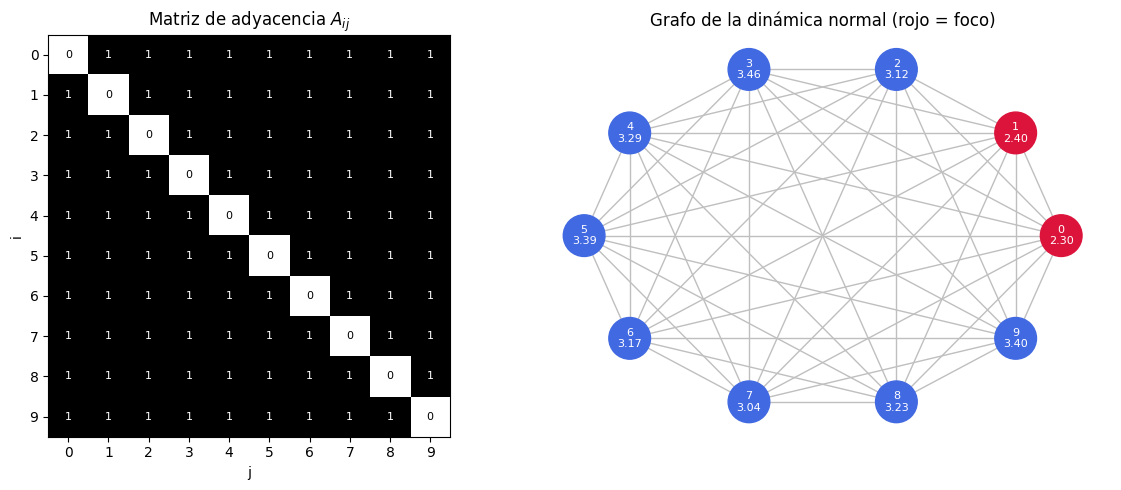

In [5]:
A = np.ones((N, N)) - np.eye(N)
G_A = nx.from_numpy_array(A)
print("Componentes conexas de A:", nx.number_connected_components(G_A))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(A, cmap="Greys", vmin=0, vmax=1)
for i in range(N):
    for j in range(N):
        ax[0].text(j, i, int(A[i, j]), ha="center", va="center", color="w" if A[i, j] else "k", fontsize=8)
ax[0].set_xticks(range(N)); ax[0].set_yticks(range(N))
ax[0].set(xlabel="j", ylabel="i", title=r"Matriz de adyacencia $A_{ij}$")
nx.draw_networkx(G_A, POS, ax=ax[1], node_color=COLOR_NODO, node_size=900,
                 labels={i: f"{i}\n{x0[i]:.2f}" for i in range(N)}, font_size=8, font_color="white",
                 edge_color="0.75")
ax[1].set_title("Grafo de la dinámica normal (rojo = foco)")
ax[1].axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "dn2_grafo_completo.png", dpi=200)
plt.show()

**Observación.** $A$ tiene **una sola componente conexa** (grafo completo, 45 aristas, todas las regiones con grado 9). La red estructural no distingue ninguna región, así que la estructura tiene que salir de la dinámica.

# **I.2 Acoplamiento crítico**

Se barre $K\in[0,2.5]$ (51 valores, $T=60000$) en una sola llamada vectorizada y se cuentan las crisis por región. $K_c$ es el primer $K$ en que alguna región sana tiene una crisis. En el resto de la Parte I se usan:

- $K_{\rm sub}=0.9\,K_c$: el foco tiene crisis y las sanas no;
- $K_{\rm sup}$: el menor $K$ del barrido en que todas las sanas tienen crisis (cascada).

In [6]:
t0 = time.time()
K_barrido = np.linspace(0, 2.5, 51)
barrido = em_red(x0, A, K_barrido, T=60000, M=len(K_barrido))
crisis = pd.DataFrame(barrido["n_on"], index=pd.Index(np.round(K_barrido, 2), name="K"),
                      columns=[f"{i}{'*' if foco[i] else ''}" for i in range(N)])
print(f"({time.time() - t0:.0f} s)   * = foco")
display(crisis[crisis.index >= 2.0].T)

K_C = K_barrido[np.argmax((barrido["n_on"][:, sanas] > 0).any(1))]
K_SUB = 0.9 * K_C
K_SUP = K_barrido[np.argmax((barrido["n_on"][:, sanas] > 0).all(1))]
print(f"K_c = {K_C:.2f}   K_sub = 0.9·K_c = {K_SUB:.3f}   K_sup = {K_SUP:.2f}")

(26 s)   * = foco


K,2.00,2.05,2.10,2.15,2.20,2.25,2.30,2.35,2.40,2.45,2.50
0*,13,13,13,13,12,12,10,8,6,6,5
1*,13,13,13,13,12,12,10,8,6,6,5
2,0,0,0,0,0,0,0,0,0,3,2
3,0,0,0,0,0,0,0,0,0,2,2
4,0,0,0,0,0,0,0,0,0,2,2
5,0,0,0,0,0,0,0,0,0,2,2
6,0,0,0,0,0,0,0,0,0,2,2
7,0,0,0,0,0,0,0,1,6,4,2
8,0,0,0,0,0,0,0,0,0,2,2
9,0,0,0,0,0,0,0,0,0,2,2


K_c = 2.35   K_sub = 0.9·K_c = 2.115   K_sup = 2.45


**Observación.** - $K_c=2.35$: la primera región sana en entrar en crisis es la **7**, la de menor $x_0$ (3.036), con una sola crisis. Antes daba ~1.8 porque la región 9 tenía $x_0=2.938$, pegada al umbral; ahora se volvió a sortear ($x_0=3.397$).
- $K_{\rm sub}=0.9\,K_c=2.115$: el foco tiene 13 crisis por nodo y ninguna sana tiene crisis.
- $K_{\rm sup}=2.45$: todas las sanas tienen crisis (2 o 3 cada una; la 7 tiene 4).
- Al subir $K$ el foco pierde crisis (13 → 5 entre $K=2.15$ y $2.5$): la mayoría sana también frena al foco.

# **I.3 Matriz de adyacencia de la dinámica normal y comunidades**

Una simulación con $K_{\rm sub}$ y otra con $K_{\rm sup}$ ($T=60000$, en la misma llamada). Para cada una: mapa de $W$, componentes conexas del grafo de consenso, las cuatro comunidades clásicas más el consenso y `tabla_crisis`.

In [7]:
det = em_red(x0, A, [K_SUB, K_SUP], T=60000, M=2, guardar=True)
print("Crisis por región:  K_sub ->", det["n_on"][0], "   K_sup ->", det["n_on"][1])

Crisis por región:  K_sub -> [13 13  0  0  0  0  0  0  0  0]    K_sup -> [6 6 3 2 2 2 2 4 2 2]


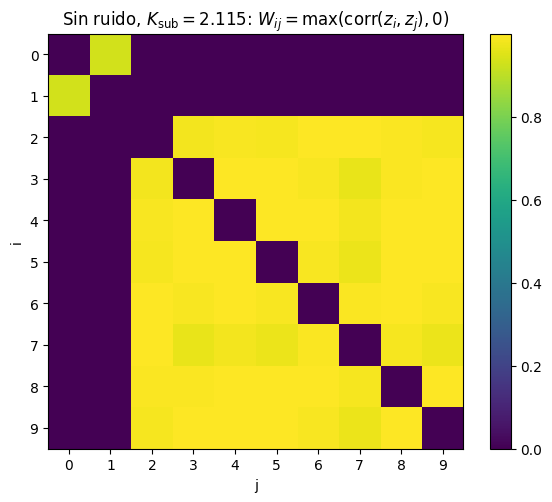

Componentes conexas del grafo de consenso: 2  ->  [[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]


,método,comunidades,Q,"ARI vs {foco, sanas}"
0,Louvain,"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.063,1.0
1,Greedy (CNM),"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.063,1.0
2,Propagación de etiquetas,"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.063,1.0
3,Espectral,"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.063,1.0
4,Consenso (50 Louvain),"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.063,1.0


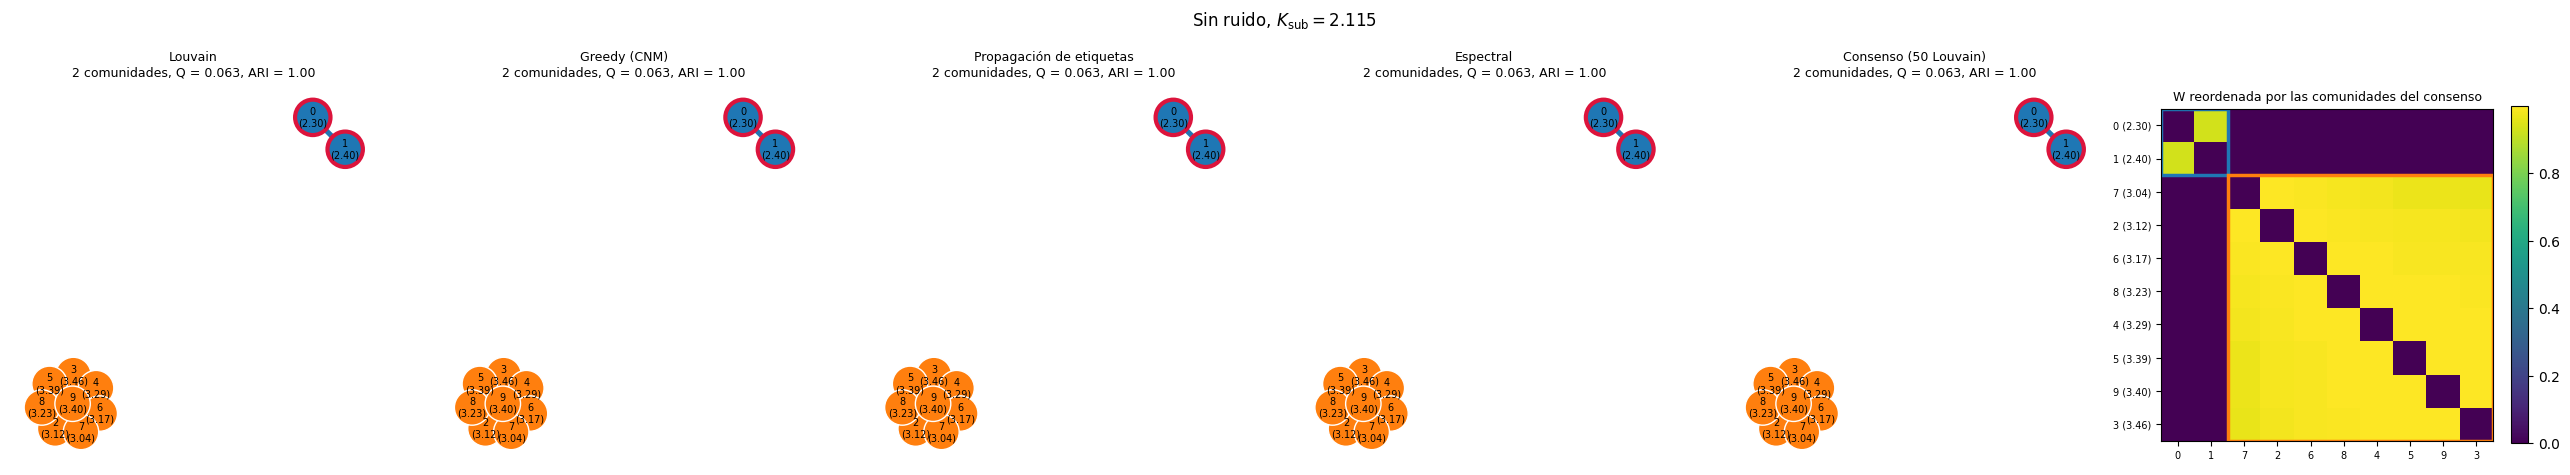

,comunidad,miembros,x0 medio,fracción del tiempo en crisis
0,0,"[0, 1]",2.350,0.119
1,1,"[2, 3, 4, 5, 6, 7, 8, 9]",3.261,0.000


In [8]:
W_sub, com_sub, tc_sub = analizar(det["z"][:, 0], det["ict"][:, 0],
                                  rf"Sin ruido, $K_{{\rm sub}}={K_SUB:.3f}$", "dn2_W_sub.png")

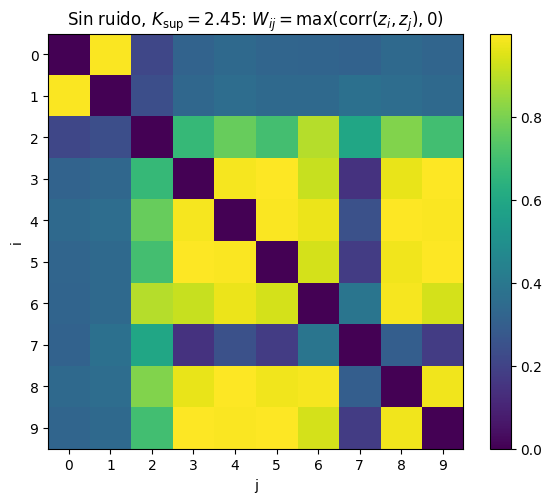

Componentes conexas del grafo de consenso: 2  ->  [[0, 1, 7], [2, 3, 4, 5, 6, 8, 9]]


,método,comunidades,Q,"ARI vs {foco, sanas}"
0,Louvain,"[[0, 1, 7], [2, 3, 4, 5, 6, 8, 9]]",0.057,0.592
1,Greedy (CNM),"[[0, 1, 7], [2, 3, 4, 5, 6, 8, 9]]",0.057,0.592
2,Propagación de etiquetas,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]",0.000,0.000
3,Espectral,"[[0, 1, 7], [2, 3, 4, 5, 6, 8, 9]]",0.057,0.592
4,Consenso (50 Louvain),"[[0, 1, 7], [2, 3, 4, 5, 6, 8, 9]]",0.057,0.592


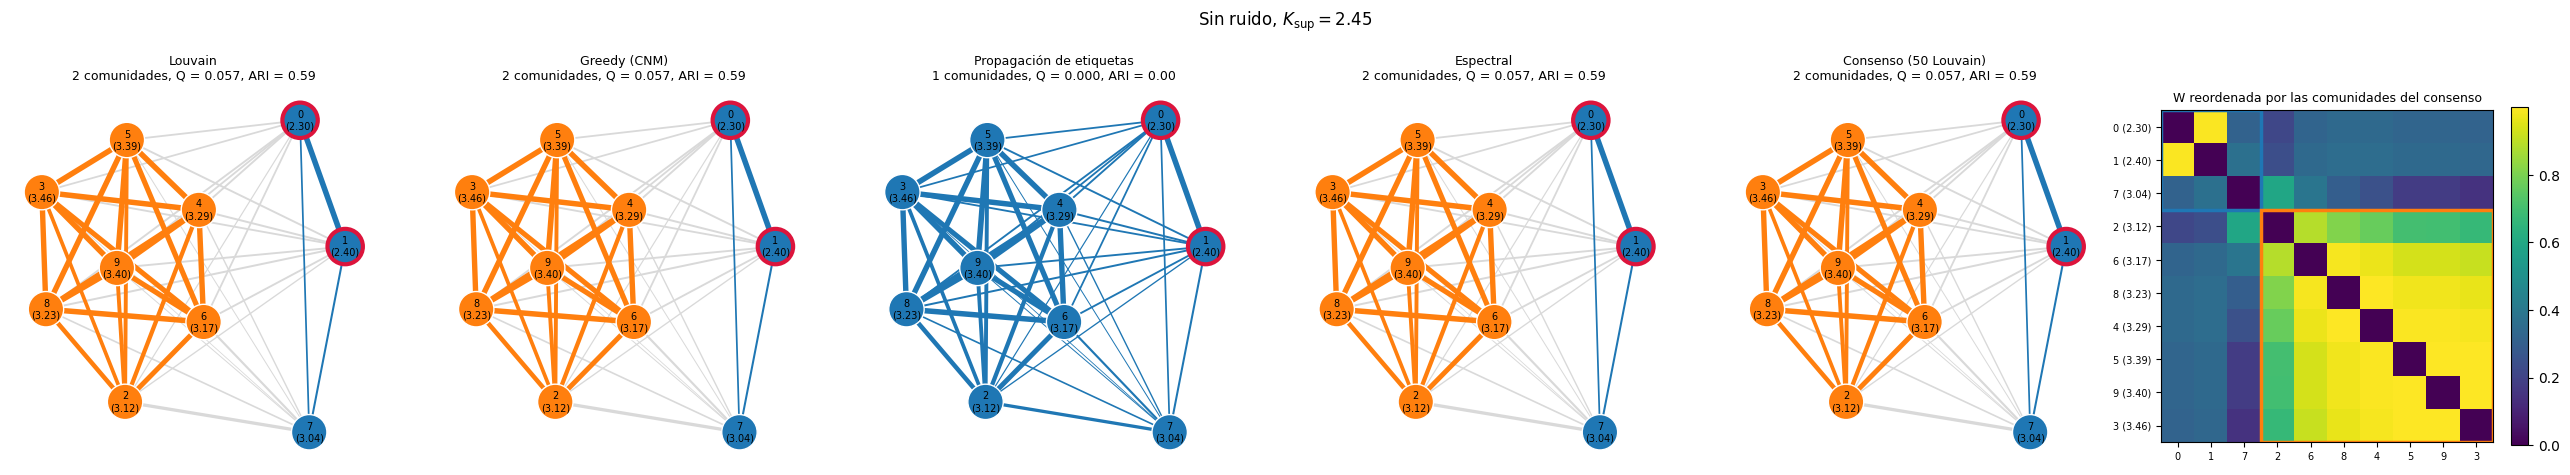

,comunidad,miembros,x0 medio,fracción del tiempo en crisis
0,0,"[0, 1, 7]",2.579,0.070
1,1,"[2, 3, 4, 5, 6, 8, 9]",3.293,0.031


In [9]:
W_sup, com_sup, tc_sup = analizar(det["z"][:, 1], det["ict"][:, 1],
                                  rf"Sin ruido, $K_{{\rm sup}}={K_SUP:.2f}$", "dn2_W_sup.png")

**Observaciones.**
- **$K_{\rm sub}$:**
  - El grafo de consenso tiene **2 componentes conexas**, $\{0,1\}$ y $\{2,\dots,9\}$, y los cinco métodos coinciden ($Q=0.063$, ARI = 1).
  - En los clusters el par del foco queda aislado, unido por una arista gruesa. Las ocho sanas forman un bloque denso y las aristas entre los dos grupos son delgadas y grises.
  - **En crisis:** la comunidad del foco, 11.9 % del tiempo; la sana, 0 %.
- **$K_{\rm sup}$:**
  - El consenso da $\{0,1,7\}$ y $\{2,3,4,5,6,8,9\}$ ($Q=0.057$, ARI = 0.59); Louvain, CNM y espectral dan lo mismo.
  - En $W$ reordenada, las sanas $\{2,\dots,9\}\setminus\{7\}$ forman un bloque muy correlacionado ($W\approx0.6$–$1$). La región 7 tiene correlaciones bajas con todas ($\lesssim0.5$; la mayor es con la 2).
  - La 7 queda con el foco más por su baja correlación con el bloque sano que por un vínculo fuerte con el foco.
  - **En crisis:** las dos comunidades, $\{0,1,7\}$ el 7.0 % del tiempo y la comunidad sana el 3.1 %.

**Comparación de los métodos.**
- **Cuando coinciden:** Louvain, CNM y el método espectral coinciden siempre. Cuando $W$ tiene dos bloques claros, como con $K_{\rm sub}$, la propagación de etiquetas también coincide con ellos.
- **Propagación de etiquetas con $K_{\rm sup}$:** junta todo en una comunidad. Durante la cascada todas las correlaciones son positivas y el grafo es denso; cada nodo adopta la etiqueta con mayor peso total entre sus vecinos, y la etiqueta del bloque sano (7 nodos con $W$ alto) termina dominando también al foco. Este método no maximiza $Q$, así que nada lo frena.
- **Por qué el consenso:** la modularidad es baja ($Q\approx0.06$), así que hay varias particiones casi igual de buenas y una sola corrida de Louvain puede cambiar con la semilla. El consenso solo junta pares que quedan juntos en más de la mitad de 50 corridas, y por eso da una partición **estable**, que es la que se usa para decidir qué comunidades están en crisis.

# **I.4 ¿Cómo entran en crisis las comunidades? (sin ruido)**

$K_{\rm sup}$, $T=150000$, comunidades de consenso en ventanas deslizantes de 4000 con paso 1000, y los clusters antes, durante y después de la primera cascada.

(41 s)   crisis por región: [18 18  9  9  9  9  9  9  9  9]


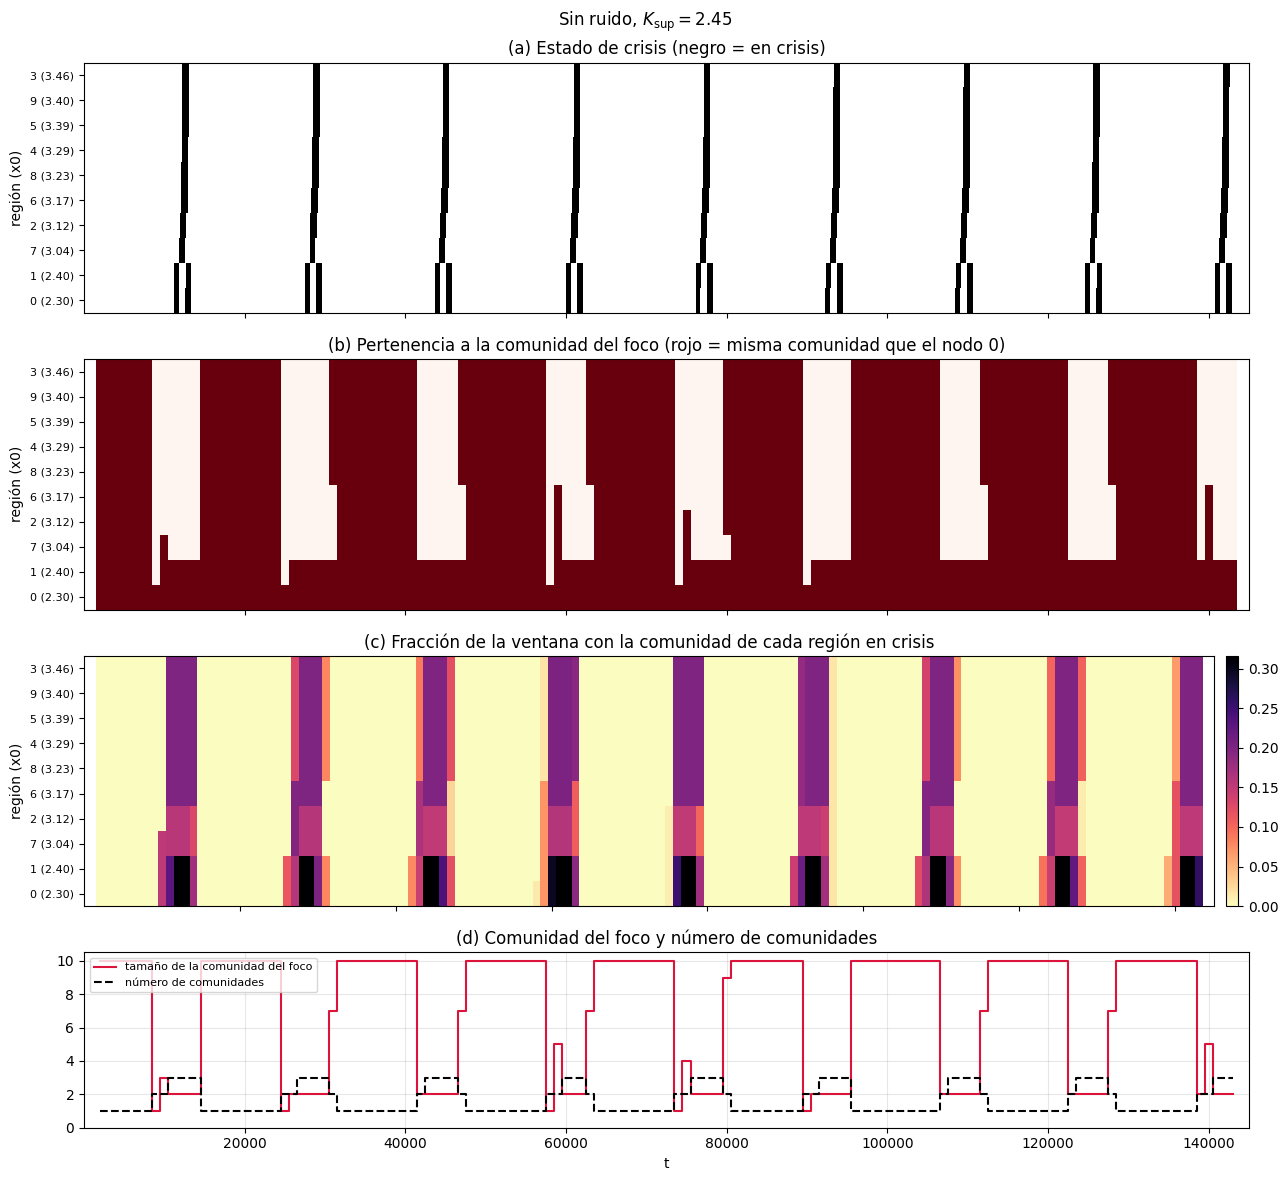

antes: t ∈ [7001, 11001], regiones en crisis a la vez: 0, sanas con crisis: 0, comunidades del consenso: [[0], [1, 2, 3, 4, 5, 6, 7, 8, 9]]


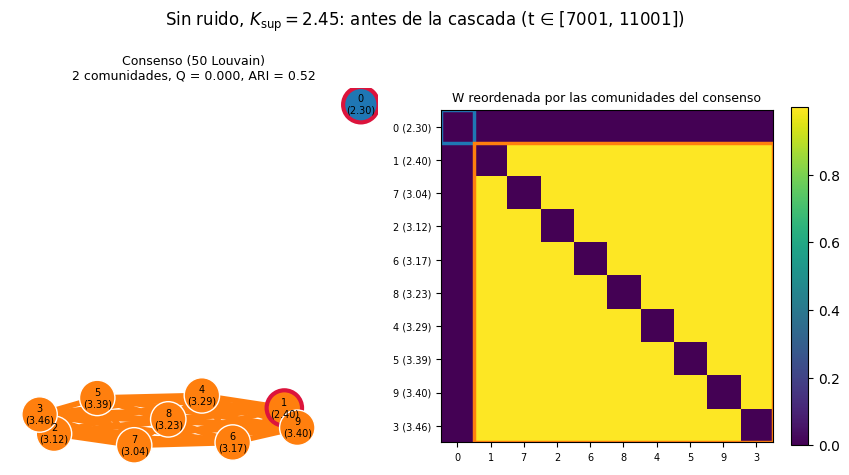

durante: t ∈ [9001, 13001], regiones en crisis a la vez: 9, sanas con crisis: 8, comunidades del consenso: [[0, 1], [2, 7], [3, 4, 5, 6, 8, 9]]


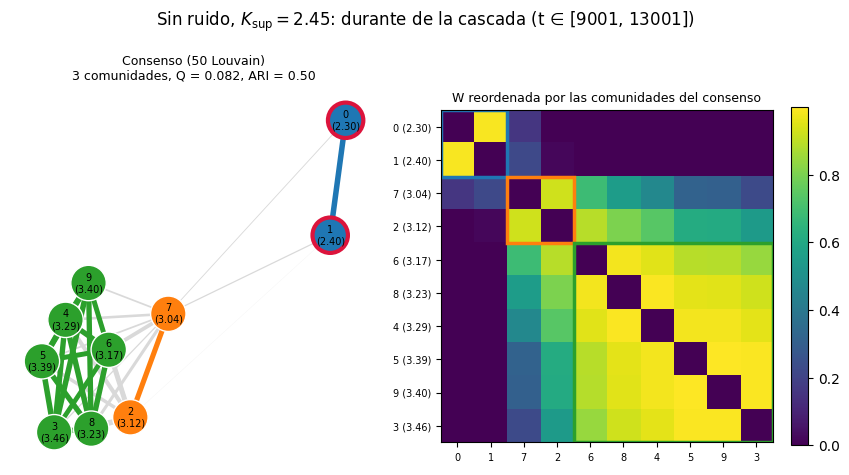

después: t ∈ [14001, 18001], regiones en crisis a la vez: 0, sanas con crisis: 0, comunidades del consenso: [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]


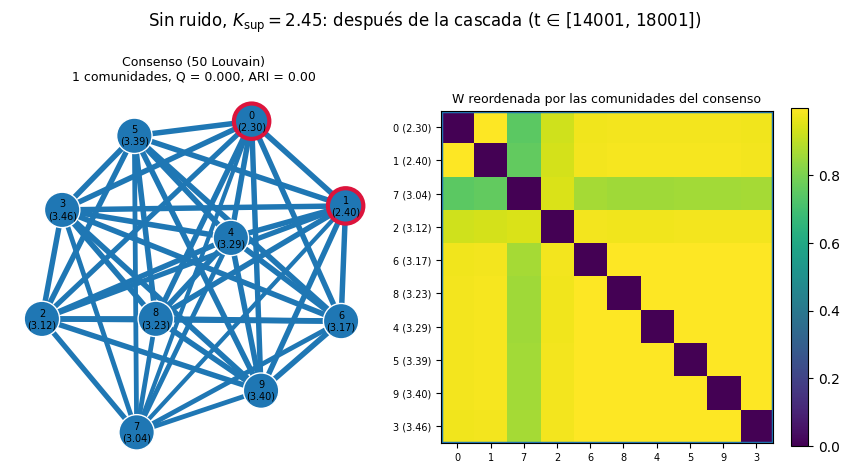

,x0,primera crisis (t),primera ventana en la comunidad del foco (t),fracción de ventanas en la comunidad del foco,fracción media en crisis de su comunidad
región,,,,,
0,2.300,11210.0,2001.0,1.000,0.074
1,2.400,11257.0,2001.0,0.965,0.074
7,3.036,11781.0,2001.0,0.641,0.041
2,3.122,11894.0,2001.0,0.641,0.040
6,3.166,12036.0,2001.0,0.634,0.050
8,3.233,12107.0,2001.0,0.655,0.050
4,3.286,12146.0,2001.0,0.655,0.050
5,3.394,12203.0,2001.0,0.655,0.050
9,3.397,12205.0,2001.0,0.655,0.050


In [10]:
t0 = time.time()
cas = em_red(x0, A, K_SUP, T=150000, guardar=True)
print(f"({time.time() - t0:.0f} s)   crisis por región:", cas["n_on"][0])
res_cas = comunidades_en_el_tiempo(cas["z"][:, 0], cas["ict"][:, 0], cas["t"],
                                   rf"Sin ruido, $K_{{\rm sup}}={K_SUP:.2f}$", "dn2_comunidades_tiempo_sin_ruido.png",
                                   ventana=4000, paso=1000, instantaneas=True)

**Observaciones.**
- **Orden de entrada:** en $T=150000$ el foco tiene 18 crisis por nodo y cada sana 9, una cascada cada ~16000. Dentro de cada cascada las sanas entran exactamente en orden creciente de $x_0$: 7 ($t=11781$) → 2 → 6 → 8 → 4 → 5 → 9 → 3 ($t=12230$).
- **Ciclo de los clusters** (ventanas de 4000, panel d), que se repite en cada cascada:
  1. **Entre cascadas** la red es **una sola comunidad**: todos los $z$ se relajan juntos.
  2. Justo **antes**, el foco se separa: en $t\in[7001,11001]$ el consenso da $\{0\}$ y $\{1,\dots,9\}$; el nodo 0 es el primero en salir.
  3. **Durante** la cascada ($t\in[9001,13001]$, 9 regiones en crisis a la vez) hay **3 comunidades**: el foco $\{0,1\}$, las dos primeras reclutadas $\{7,2\}$ y el resto $\{3,4,5,6,8,9\}$, ordenadas por $x_0$.
  4. **Después** ($t\in[14001,18001]$) la red vuelve a ser **una sola comunidad**.
- Así, durante la cascada la comunidad sana no se une al foco: entra en crisis **como bloque propio**, y las regiones de menor $x_0$ (7 y 2) se separan de él como un subgrupo que entra primero.
- Las sanas comparten comunidad con el foco en ~64 % de las ventanas, pero eso ocurre en los periodos tranquilos, no durante las crisis.

# **Parte II: Dinámica normal con ruido**

# **II.1 Ruido**

Ruido: $\sigma_x=0.02$ y $\sigma_z=7.5\times10^{-4}$.

**Control:** 20 realizaciones con $K=0$ y el mismo ruido. Ninguna región sana debe entrar en crisis.

**Acoplamiento con ruido:** se barre $K\in[0.90,\,0.99]\,K_c$ sin ruido y con ruido (10 realizaciones por $K$). $K_{\rm ruido}$ es el $K$ más cercano a $K_c$ en que **sin ruido no hay reclutamiento y con ruido sí**: el menor $K$ de la grilla con 0 crisis sanas sin ruido y al menos 4 regiones sanas reclutadas con ruido (si no hay ninguno, el mayor $K$ con 0 crisis sanas sin ruido).

In [11]:
SX, SZ = 0.02, 7.5e-4
R = 20

t0 = time.time()
control = em_red(x0, A, 0.0, SX, SZ, T=100000, M=R, seed=1)
print(f"σx = {SX}, σz = {SZ:g}")
print("Control K = 0: crisis sanas en las", R, "realizaciones =", control["n_on"][:, sanas].sum(),
      "   crisis por región:", control["n_on"].sum(0))

K_GRID = np.linspace(0.90, 0.99, 10) * K_C
R_GRID = 10
det_grid = em_red(x0, A, K_GRID, T=60000, M=len(K_GRID))
rui_grid = em_red(x0, A, np.repeat(K_GRID, R_GRID), SX, SZ, T=100000, M=R_GRID * len(K_GRID), seed=3)
crisis_sanas_det = det_grid["n_on"][:, sanas].sum(1)
reclutadas = (rui_grid["n_on"][:, sanas] > 0).sum(1).reshape(len(K_GRID), R_GRID).mean(1)
print(f"({time.time() - t0:.0f} s)")
display(pd.DataFrame({"K": K_GRID, "K/K_c": K_GRID / K_C, "crisis sanas sin ruido": crisis_sanas_det,
                      "regiones sanas reclutadas con ruido (media)": reclutadas}).round(3))

ok = (crisis_sanas_det == 0) & (reclutadas >= 4)
K_RUIDO = K_GRID[ok][0] if ok.any() else K_GRID[crisis_sanas_det == 0].max()
print(f"K_ruido = {K_RUIDO:.3f}   K_ruido / K_c = {K_RUIDO / K_C:.2f}")

σx = 0.02, σz = 0.00075
Control K = 0: crisis sanas en las 20 realizaciones = 0    crisis por región: [380 360   0   0   0   0   0   0   0   0]


(156 s)


,K,K/K_c,crisis sanas sin ruido,regiones sanas reclutadas con ruido (media)
0,2.115,0.90,0,0.6
1,2.138,0.91,0,0.7
2,2.162,0.92,0,0.7
3,2.186,0.93,0,1.2
4,2.209,0.94,0,0.7
5,2.232,0.95,0,1.3
6,2.256,0.96,0,0.6
7,2.280,0.97,0,1.4
8,2.303,0.98,0,1.1
9,2.327,0.99,0,0.8


K_ruido = 2.327   K_ruido / K_c = 0.99


**Observaciones.**
- **Control $K=0$:** 0 crisis en todas las regiones sanas en las 20 realizaciones ($T=100000$); el foco tiene 380 y 360.
- **Sin ruido** no hay ninguna crisis sana en toda la grilla $K\in[0.90,\,0.99]\,K_c$.
- **Con ruido** el número medio de sanas reclutadas va de 0.6 a 1.4 por realización, sin tendencia clara con $K$, y **ningún $K$ llega a 4**. Por eso se usa el criterio de respaldo: $K_{\rm ruido}=2.327=0.99\,K_c$, el mayor $K$ sin crisis sanas sin ruido.

# **II.2 Matriz de adyacencia y comunidades con ruido**

Una realización con $K_{\rm ruido}$ ($T=300000$). Mismos pasos que en I.3.

(113 s)   crisis por región: [74 74  0  0  0  0  0  3  0  0]


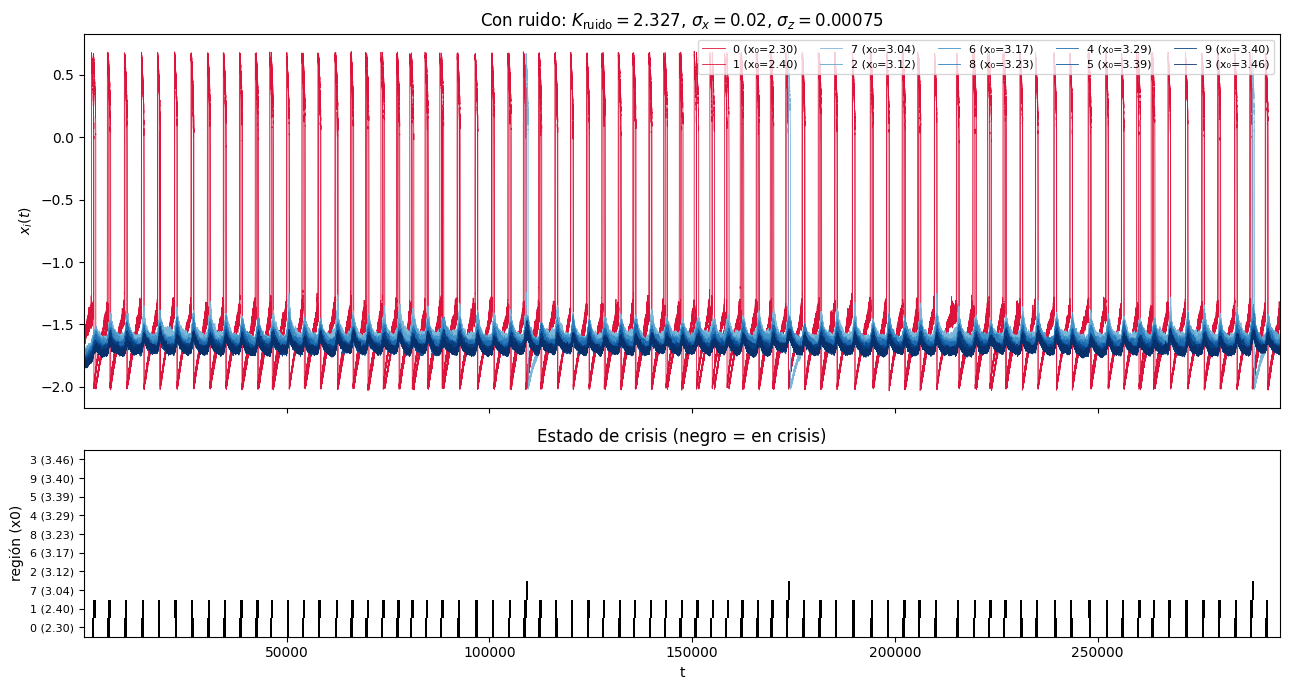

In [12]:
def graficar_series(t, X, S, titulo, archivo):
    fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    for k, i in enumerate(ORDEN):
        ax[0].plot(t, X[:, i], lw=0.6, color="crimson" if foco[i] else plt.cm.Blues(0.3 + 0.08 * k),
                   label=f"{i} (x₀={x0[i]:.2f})")
    ax[0].set(ylabel="$x_i(t)$", title=titulo)
    ax[0].legend(ncol=5, fontsize=8, loc="upper right")
    ax[1].imshow(S[:, ORDEN].T, aspect="auto", origin="lower", cmap="Greys", interpolation="nearest",
                 extent=[t[0], t[-1], -0.5, N - 0.5])
    ax[1].set_yticks(range(N), [f"{i} ({x0[i]:.2f})" for i in ORDEN], fontsize=8)
    ax[1].set(xlabel="t", ylabel="región (x0)", title="Estado de crisis (negro = en crisis)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / archivo, dpi=200)
    plt.show()

t0 = time.time()
rui = em_red(x0, A, K_RUIDO, SX, SZ, T=300000, seed=7, guardar=True)
print(f"({time.time() - t0:.0f} s)   crisis por región:", rui["n_on"][0])
graficar_series(rui["t"], rui["x"][:, 0], rui["ict"][:, 0],
                rf"Con ruido: $K_{{\rm ruido}}={K_RUIDO:.3f}$, $\sigma_x={SX}$, $\sigma_z={SZ:g}$", "dn2_series_con_ruido.png")

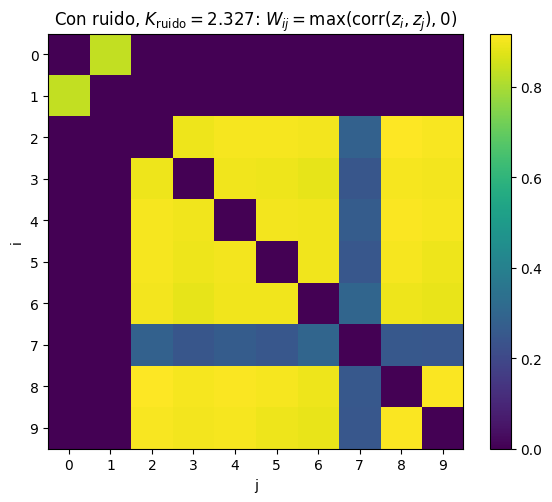

Componentes conexas del grafo de consenso: 2  ->  [[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]


,método,comunidades,Q,"ARI vs {foco, sanas}"
0,Louvain,"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.074,1.0
1,Greedy (CNM),"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.074,1.0
2,Propagación de etiquetas,"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.074,1.0
3,Espectral,"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.074,1.0
4,Consenso (50 Louvain),"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.074,1.0


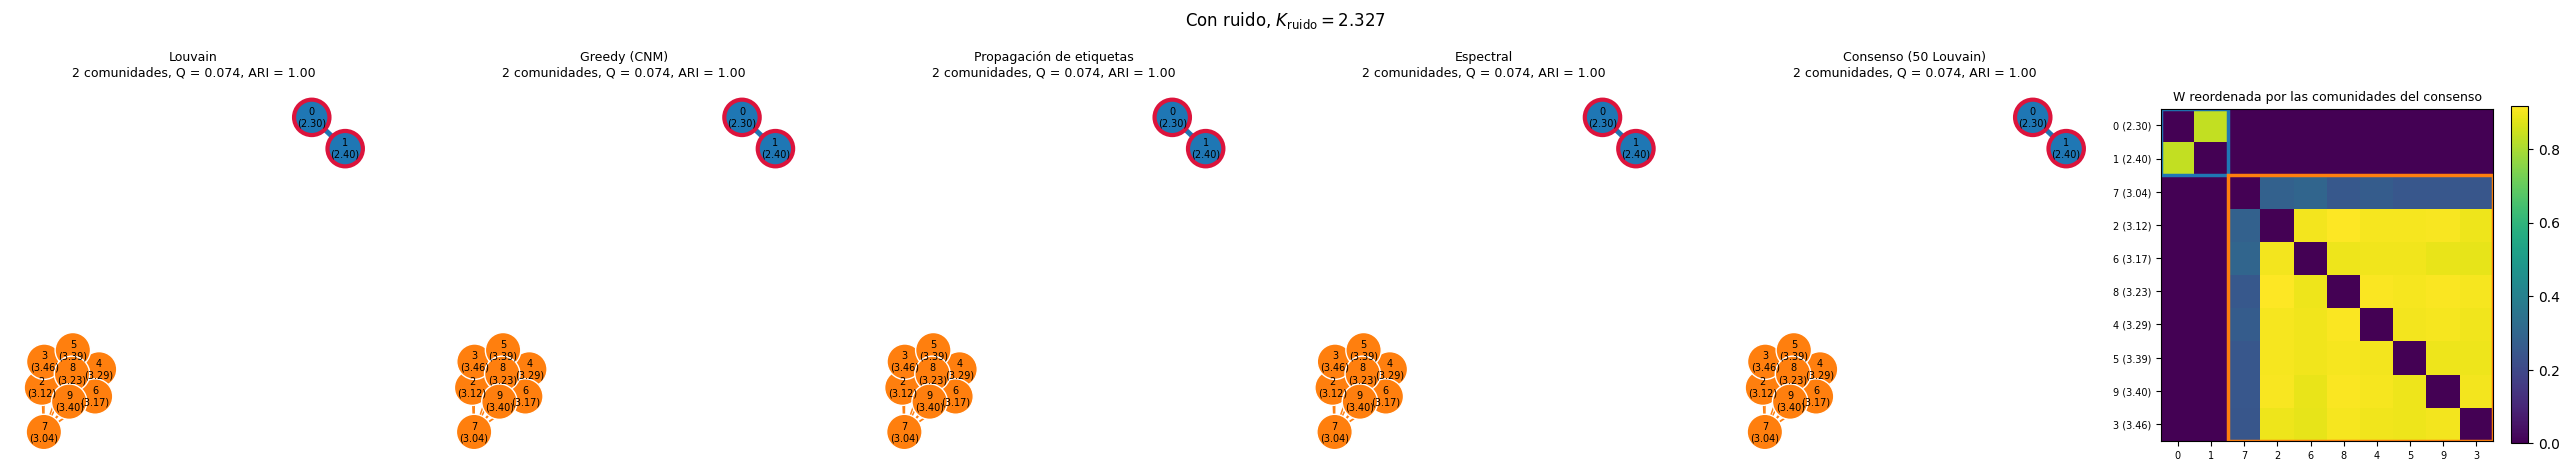

,comunidad,miembros,x0 medio,fracción del tiempo en crisis
0,0,"[0, 1]",2.350,0.102
1,1,"[2, 3, 4, 5, 6, 7, 8, 9]",3.261,0.000


In [13]:
W_rui, com_rui, tc_rui = analizar(rui["z"][:, 0], rui["ict"][:, 0],
                                  rf"Con ruido, $K_{{\rm ruido}}={K_RUIDO:.3f}$", "dn2_W_ruido.png")

**Observaciones.**
- En la realización con $K_{\rm ruido}$ ($T=300000$) el foco tiene 74 crisis por nodo, la **región 7 tiene 3** y las demás sanas, ninguna.
- El grafo de consenso tiene **2 componentes conexas**, $\{0,1\}$ y $\{2,\dots,9\}$, y los cinco métodos coinciden ($Q=0.074$, ARI = 1). Los clusters se ven igual que con $K_{\rm sub}$ sin ruido: el foco aislado y las sanas en un bloque.
- **En crisis:** la comunidad del foco, 10.2 % del tiempo; la sana, 0 % (las crisis de la región 7 no alcanzan a la mitad de su comunidad).

# **II.3 ¿Cómo entran en crisis las comunidades? (con ruido)**

## **Comunidades en el tiempo (realización de II.2)**

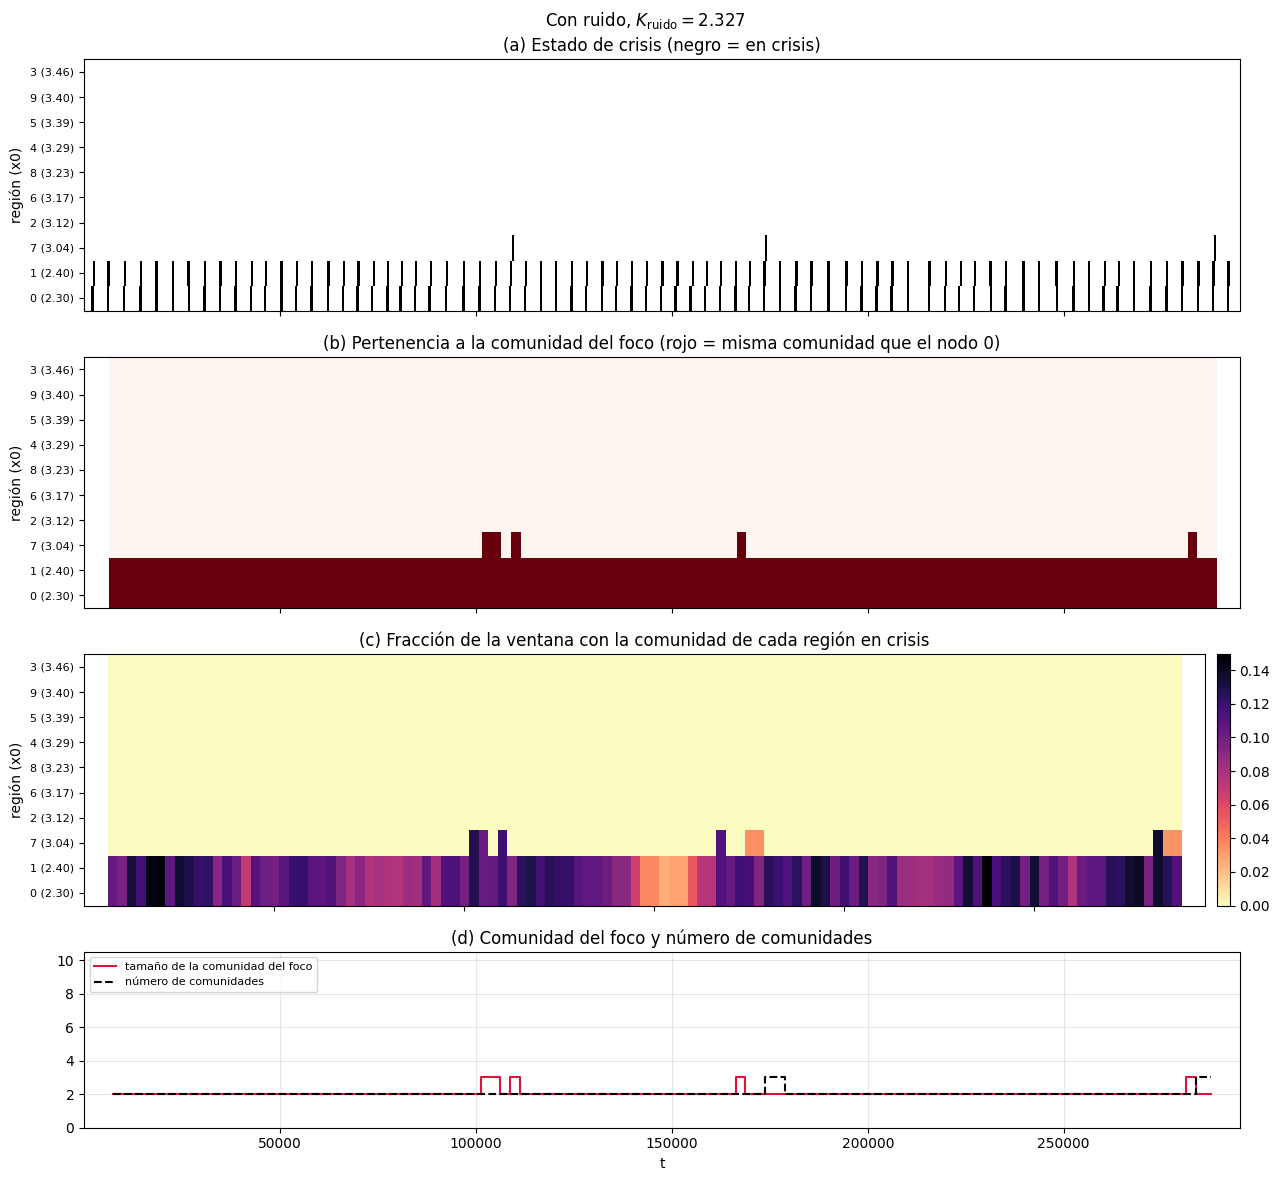

,x0,primera crisis (t),primera ventana en la comunidad del foco (t),fracción de ventanas en la comunidad del foco,fracción media en crisis de su comunidad
región,,,,,
0,2.300,1859.0,7501.0,1.000,0.104
1,2.400,2335.0,7501.0,1.000,0.104
7,3.036,109037.0,102501.0,0.044,0.007
2,3.122,NaN,NaN,0.000,0.000
6,3.166,NaN,NaN,0.000,0.000
8,3.233,NaN,NaN,0.000,0.000
4,3.286,NaN,NaN,0.000,0.000
5,3.394,NaN,NaN,0.000,0.000
9,3.397,NaN,NaN,0.000,0.000


In [14]:
res_rui = comunidades_en_el_tiempo(rui["z"][:, 0], rui["ict"][:, 0], rui["t"],
                                   rf"Con ruido, $K_{{\rm ruido}}={K_RUIDO:.3f}$", "dn2_comunidades_tiempo_con_ruido.png")

## **Resumen sobre realizaciones: $K=0$ contra $K_{\rm ruido}$**

20 realizaciones con $K=0$ y 20 con $K_{\rm ruido}$ ($T=100000$), en una sola llamada. En cada realización se calcula el consenso sobre $W$ y, por región sana, si queda en la misma comunidad que el foco (nodo 0) y la fracción del tiempo con su comunidad en crisis.

(59 s)


,x0,P(misma comunidad que el foco) K=0,P(misma comunidad que el foco) K_ruido,fracción del tiempo con su comunidad en crisis K=0,fracción del tiempo con su comunidad en crisis K_ruido,crisis por realización K_ruido
región sana,,,,,,
7,3.036,0.25,0.0,0.000,0.001,1.00
2,3.122,0.30,0.0,0.000,0.000,0.10
6,3.166,0.20,0.0,0.000,0.001,0.10
8,3.233,0.35,0.0,0.006,0.000,0.05
4,3.286,0.35,0.0,0.000,0.000,0.05
5,3.394,0.25,0.0,0.000,0.000,0.05
9,3.397,0.15,0.0,0.000,0.000,0.05
3,3.456,0.45,0.0,0.009,0.000,0.05


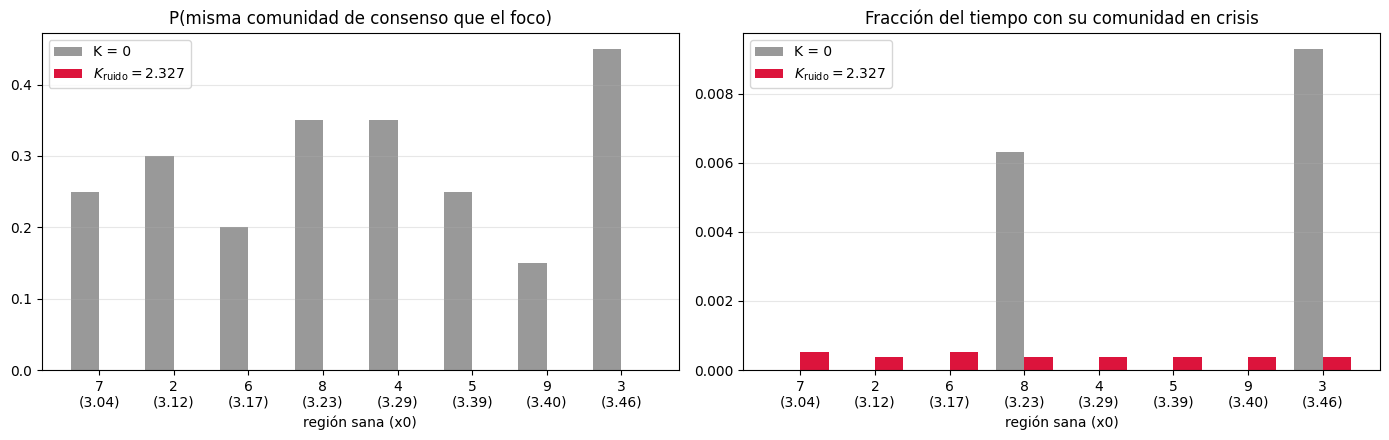

In [15]:
t0 = time.time()
rea = em_red(x0, A, np.repeat([0.0, K_RUIDO], R), SX, SZ, T=100000, M=2 * R, seed=11, guardar=True)
print(f"({time.time() - t0:.0f} s)")

misma = np.zeros((2 * R, N)); frac_com = np.zeros((2 * R, N))
for m in range(2 * R):
    S_m = rea["ict"][:, m]
    com, _ = comunidades_consenso(matriz_dinamica(rea["z"][:, m]))
    misma[m, next(c for c in com if 0 in c)] = 1
    for c in com:
        frac_com[m, c] = en_crisis(S_m, c).mean()

idx_sanas = ORDEN[sanas[ORDEN]]
resumen_rea = pd.DataFrame({"x0": x0[idx_sanas],
                            "P(misma comunidad que el foco) K=0": misma[:R, idx_sanas].mean(0),
                            "P(misma comunidad que el foco) K_ruido": misma[R:, idx_sanas].mean(0),
                            "fracción del tiempo con su comunidad en crisis K=0": frac_com[:R, idx_sanas].mean(0),
                            "fracción del tiempo con su comunidad en crisis K_ruido": frac_com[R:, idx_sanas].mean(0),
                            "crisis por realización K_ruido": rea["n_on"][R:, idx_sanas].mean(0)},
                           index=pd.Index(idx_sanas, name="región sana"))
display(resumen_rea.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
xs = np.arange(len(idx_sanas)); ancho = 0.38
etiq = [f"{i}\n({x0[i]:.2f})" for i in idx_sanas]
for a, col, tit in [(ax[0], "P(misma comunidad que el foco)", "P(misma comunidad de consenso que el foco)"),
                    (ax[1], "fracción del tiempo con su comunidad en crisis", "Fracción del tiempo con su comunidad en crisis")]:
    a.bar(xs - ancho / 2, resumen_rea[f"{col} K=0"], ancho, color="0.6", label="K = 0")
    a.bar(xs + ancho / 2, resumen_rea[f"{col} K_ruido"], ancho, color="crimson", label=rf"$K_{{\rm ruido}}={K_RUIDO:.3f}$")
    a.set_xticks(xs, etiq)
    a.set(xlabel="región sana (x0)", title=tit)
    a.grid(alpha=0.3, axis="y"); a.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "dn2_resumen_realizaciones.png", dpi=200)
plt.show()

## **Una cascada con ruido**

La realización con $K_{\rm ruido}$ en que todas las sanas tienen crisis, en ventanas de 4000 con paso 1000.

Realización 18 con K_ruido; crisis por región: [23 23  1  1  1  1  1  2  1  1]


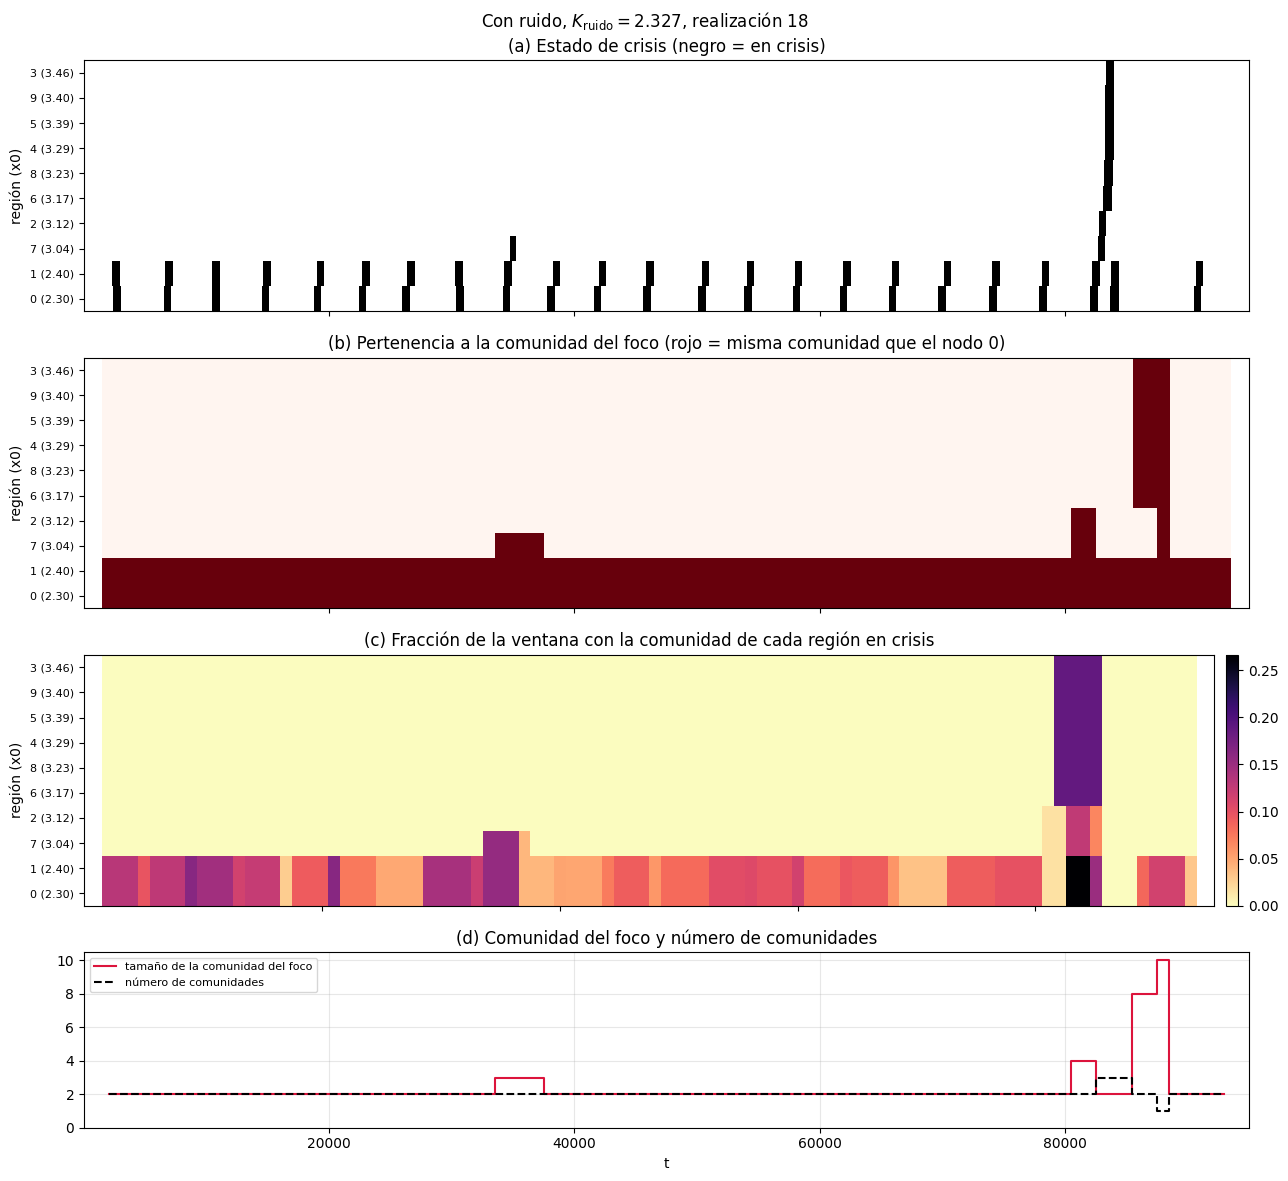

antes: t ∈ [78001, 82001], regiones en crisis a la vez: 2, sanas con crisis: 0, comunidades del consenso: [[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]


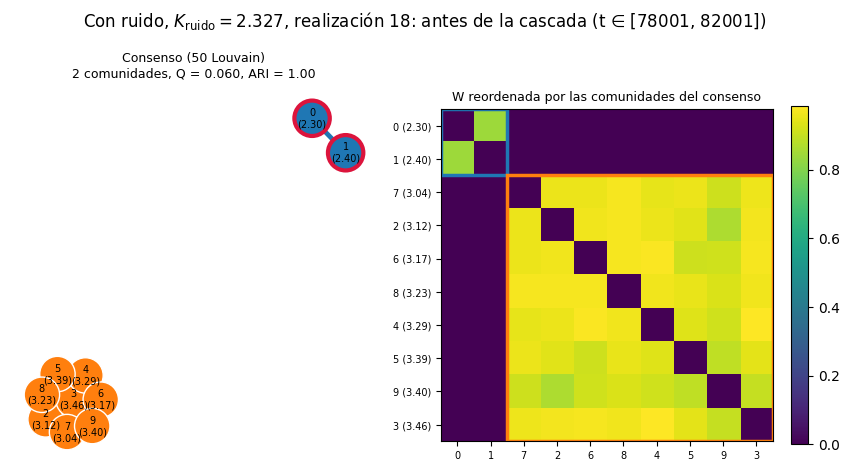

durante: t ∈ [80001, 84001], regiones en crisis a la vez: 8, sanas con crisis: 8, comunidades del consenso: [[0, 1, 2, 7], [3, 4, 5, 6, 8, 9]]


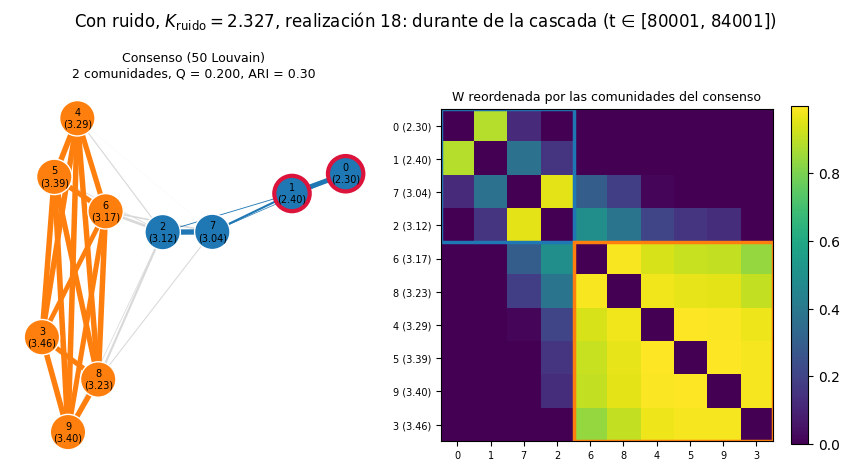

después: t ∈ [85001, 89001], regiones en crisis a la vez: 0, sanas con crisis: 0, comunidades del consenso: [[0, 1, 3, 4, 5, 6, 8, 9], [2, 7]]


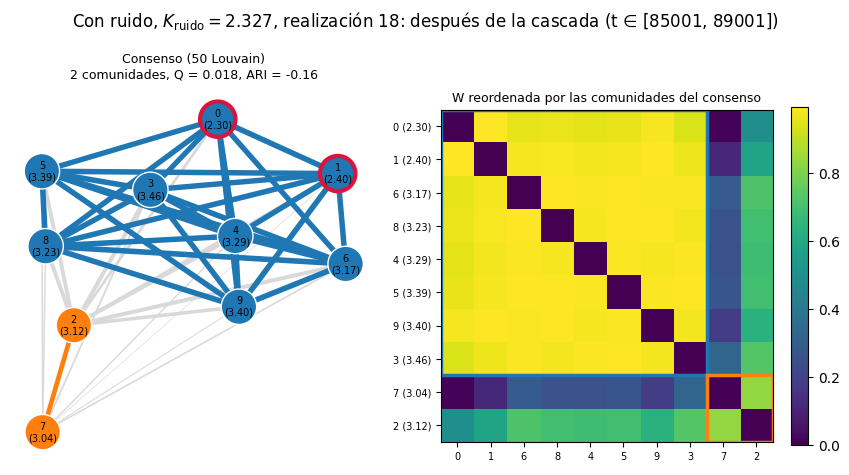

,x0,primera crisis (t),primera ventana en la comunidad del foco (t),fracción de ventanas en la comunidad del foco,fracción media en crisis de su comunidad
región,,,,,
0,2.300,2384.0,2001.0,1.000,0.094
1,2.400,2314.0,2001.0,1.000,0.094
7,3.036,34742.0,34001.0,0.076,0.009
2,3.122,82761.0,81001.0,0.033,0.004
6,3.166,83096.0,86001.0,0.033,0.008
8,3.233,83143.0,86001.0,0.033,0.008
4,3.286,83220.0,86001.0,0.033,0.008
5,3.394,83249.0,86001.0,0.033,0.008
9,3.397,83251.0,86001.0,0.033,0.008


In [16]:
con_cascada = [m for m in range(R, 2 * R) if (rea["n_on"][m, sanas] > 0).all()]
if con_cascada:
    m = con_cascada[0]
    print(f"Realización {m - R} con K_ruido; crisis por región:", rea["n_on"][m])
    res_cas_rui = comunidades_en_el_tiempo(rea["z"][:, m], rea["ict"][:, m], rea["t"],
                                           rf"Con ruido, $K_{{\rm ruido}}={K_RUIDO:.3f}$, realización {m - R}",
                                           "dn2_cascada_con_ruido.png", ventana=4000, paso=1000, instantaneas=True)
else:
    print("Ninguna realización con K_ruido tiene crisis en todas las regiones sanas.")

**Observaciones.**
- **Realización larga** (ventanas de 15000): la comunidad del foco es $\{0,1\}$ en casi todas las ventanas. Solo absorbe a la **región 7**, la de menor $x_0$, en las ventanas con sus crisis (4.4 % de las ventanas; primera crisis en $t=109037$).
- **Sobre realizaciones con $K_{\rm ruido}$:**
  - la región 7 tiene 1.0 crisis por realización, las regiones 2 y 6 tienen 0.10 y las demás 0.05. Ese 0.05 corresponde a **una** realización (la 18), con una cascada completa disparada por el ruido;
  - $P(\text{misma comunidad que el foco})$ sobre la realización completa es 0 con $K_{\rm ruido}$, contra 0.15–0.45 con $K=0$ (agrupación al azar de $z$ independientes).
- **Cascada con ruido (realización 18, ventanas de 4000).**
  - **Entrada:** la región 7 ya había tenido una crisis suelta ($t=34742$). La cascada empieza en $t\approx82700$ y entra en orden de $x_0$: 2 ($t=82761$) → 6 → 8 → 4 → 5 → 9 → 3 ($t=83303$).
  - **Antes** ($t\in[78001,82001]$): $\{0,1\}$ y $\{2,\dots,9\}$, como en II.2.
  - **Durante** ($t\in[80001,84001]$): $\{0,1,2,7\}$ y $\{3,4,5,6,8,9\}$. Las dos primeras reclutadas **se unen a la comunidad del foco**, cosa que sin ruido no ocurría (allí $\{7,2\}$ formaba su propia comunidad). El resto de las sanas entra en crisis como bloque.
  - **Después** ($t\in[85001,89001]$): $\{0,1,3,4,5,6,8,9\}$ y $\{2,7\}$. El foco y el bloque tardío se relajan juntos y las primeras reclutadas quedan aparte.

# **Conclusión**

1. **Matriz de adyacencia de la dinámica normal.** La red estructural ($A_{ij}=1$) es una sola componente conexa y no distingue regiones. La matriz dinámica $W_{ij}=\max(\operatorname{corr}(z_i,z_j),0)$ sí lo hace: tiene un bloque $\{0,1\}$ (foco) y un bloque de las sanas, con 2 componentes conexas en el grafo de consenso ($Q\approx0.06$–$0.08$).
2. **Sin ruido.**
   - Con $K_{\rm sub}=2.115$ todos los métodos detectan $\{0,1\}$ y $\{2,\dots,9\}$ (ARI = 1): el foco aislado y las sanas en un bloque denso. Solo la comunidad del foco está en crisis (11.9 % del tiempo).
   - Con $K_{\rm sup}=2.45$ el consenso da $\{0,1,7\}$ y el resto (ARI = 0.59), y **las dos comunidades** entran en crisis (7.0 % y 3.1 % del tiempo). La propagación de etiquetas junta todo; el consenso es la partición estable.
   - **Cascada:** las sanas entran en orden estricto de $x_0$ (7 → 2 → 6 → 8 → 4 → 5 → 9 → 3, en ~450 unidades de tiempo). Los clusters siguen un ciclo:
     1. una sola comunidad entre cascadas;
     2. el foco se separa justo antes;
     3. durante, tres comunidades: $\{0,1\}$, $\{7,2\}$ y el resto;
     4. después, otra vez una sola comunidad.
   - La comunidad sana entra en crisis **en bloque**, sin unirse al foco.
3. **Con ruido** ($\sigma_x=0.02$, $\sigma_z=7.5\times10^{-4}$, $K_{\rm ruido}=2.327=0.99\,K_c$, donde sin ruido no hay reclutamiento).
   - En la grilla $0.90$–$0.99\,K_c$ ningún $K$ recluta en promedio 4 sanas (máximo 1.4).
   - El reclutamiento es **de todo o nada**:
     - casi siempre entra sola la región de menor $x_0$, la **7** (1.0 crisis por realización), y solo en esas ventanas se une a la comunidad del foco;
     - en 1 de 20 realizaciones el ruido dispara una cascada completa.
   - En esa cascada el orden vuelve a ser el de $x_0$ y aparece la diferencia con el caso sin ruido: durante la cascada las primeras reclutadas (7 y 2) **se unen a la comunidad del foco**, $\{0,1,2,7\}$, mientras el resto entra en crisis como bloque propio. Después, el foco se reagrupa con las sanas tardías y $\{2,7\}$ queda aparte.
   - Con $K=0$ no hay crisis sanas y las sanas caen en la comunidad del foco solo por azar (15–45 %). Con $K_{\rm ruido}$, sobre la realización completa, forman siempre una comunidad propia (0 %).
   - El contraste pedido aparece solo en parte: con ruido las regiones de menor $x_0$ entran de a una y, durante una cascada, se unen al foco; pero la mayoría de las sanas sigue entrando en bloque.